In [1]:
#julia -t 4

using Plots
using Random, Statistics, Distributions
using SparseArrays
using LinearAlgebra
using DifferentialEquations
using StatsPlots 

using Statistics 
using Distributions, Random, Plots, StatsBase  
using Base.Threads



include("../GPs.jl")

include("../util_shoji.jl")


SOR (generic function with 1 method)

Maximum error = 0.003437095423977736
L2 error       = 0.008081096003744053


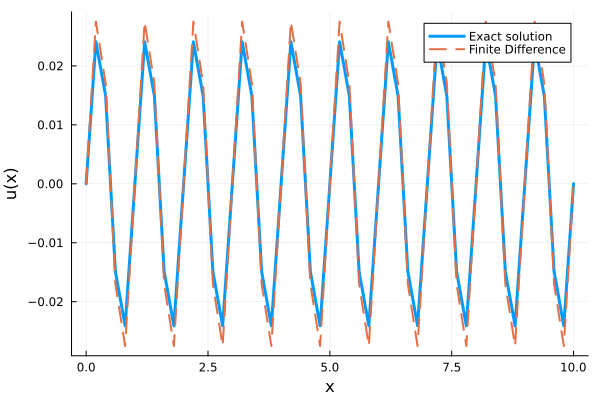

In [2]:
using LinearAlgebra
using Plots

# -----------------------------
# Problem setting
# -----------------------------

dt = 0.2
T = 10.0
x = 0:dt:T


xi = x[2:end-1]
n = length(xi)

# -----------------------------
# Construct finite difference matrix
# u'' =  - sin(2πx)
# -----------------------------
A = zeros(n, n)

for i in 1:n
    A[i,i] = - 2.0
    if i > 1
        A[i,i-1] =  1.0
    end
    if i < n
        A[i,i+1] = 1.0
    end
end

A ./= (dt)^2

# Right-hand side
f =  - sin.(2π .* xi)

# Solve linear system
u_interior = A \ f
#u_interior = sor(A, f)

# Include boundary values
u_num = vcat(0.0, u_interior, 0.0)

# -----------------------------
# Exact solution
# -----------------------------
u_exact_vec = (1/(2π)^2) .* sin.(2π .* x)

# -----------------------------
# Error
# -----------------------------
max_error = maximum(abs.(u_num .- u_exact_vec))
l2_error = sqrt(sum((u_num .- u_exact_vec).^2) * (dt))

println("Maximum error = ", max_error)
println("L2 error       = ", l2_error)

# -----------------------------
# Plot
# -----------------------------
plot(x, u_exact_vec,
    lw=3,
    label="Exact solution",
    xlabel="x",
    ylabel="u(x)")

plot!(x, u_num,
    linestyle=:dash,
    lw=2,
    label="Finite Difference")

In [3]:




X_train = collect(0:dt:T)
y_train = -sin.(2π .* X_train)



println("X_train:", X_train)
println("y_train:", y_train)

println(y_train.size)

 
#

X_train:[0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0, 3.2, 3.4, 3.6, 3.8, 4.0, 4.2, 4.4, 4.6, 4.8, 5.0, 5.2, 5.4, 5.6, 5.8, 6.0, 6.2, 6.4, 6.6, 6.8, 7.0, 7.2, 7.4, 7.6, 7.8, 8.0, 8.2, 8.4, 8.6, 8.8, 9.0, 9.2, 9.4, 9.6, 9.8, 10.0]
y_train:[-0.0, -0.9510565162951535, -0.5877852522924732, 0.587785252292473, 0.9510565162951536, 2.4492935982947064e-16, -0.9510565162951535, -0.5877852522924734, 0.5877852522924728, 0.9510565162951538, 4.898587196589413e-16, -0.951056516295154, -0.5877852522924736, 0.5877852522924726, 0.9510565162951538, 7.347880794884119e-16, -0.9510565162951533, -0.5877852522924738, 0.5877852522924725, 0.9510565162951539, 9.797174393178826e-16, -0.9510565162951533, -0.5877852522924711, 0.5877852522924694, 0.951056516295154, 1.2246467991473533e-15, -0.9510565162951532, -0.5877852522924742, 0.587785252292472, 0.951056516295154, 1.4695761589768238e-15, -0.9510565162951531, -0.5877852522924744, 0.5877852522924718, 0.9510565162951541, 1.71450551

In [4]:
#ℓ = best_ℓ
ℓ = 0.2
σf = 0.01
C = 0.01

l=1000.0
σf=0.001
C=0.001

l=0.37275937203149406
σf=0.0517947467923121
C=0.001


# -------------------------
# Test Points
# -------------------------
#X_test = collect(range(-5, 5, length=300))

X_test = collect(range(0, T, length=300))
# -------------------------
# Covariance Matrices
# -------------------------



function laplacian_matrix(n, dt)

    # n = number of grid points (including boundary)
    D = zeros(n-2, n)

    #for i in 1:n-2
    #    D[i,i+1] = 1
    #end

    for i in 1:n-2
        D[i,i]   = 1
        D[i,i+1] = - 2
        D[i,i+2] = 1
    end

    return D ./ dt^2
end




function observation_matrix(n, dt)

    D = laplacian_matrix(n, dt)

    H = zeros(n, n)

    # u(0)
    H[1,1] = 1.0

    # Lu (internal)
    H[2:n-1, :] .= D

    # u(1)
    H[end,end] = 1.0

    return H
end

H = observation_matrix(length(X_train), dt)

#println("H:", H)
##println("H.size:", H.size)



#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) +
#    σn^2 * I

# ノイズ共分散：内点は C*dt^4，境界点は 0（論文 eq. 3.3）
n_train = length(X_train)
noise_diag = fill(C * dt^4, n_train)
noise_diag[1]   = 0.0   # 境界ノイズ = 0
noise_diag[end] = 0.0   # 境界ノイズ = 0
Σ_noise = Diagonal(noise_diag)

K =
    H * kernel_matrix(X_train, X_train;
                  ℓ=ℓ, σf=σf) * H' +
    Σ_noise

# 安定化項：境界点（ノイズ=0）は大きめに
jitter = fill(1e-10, n_train)
jitter[1]   = 1e-8
jitter[end] = 1e-8
K += Diagonal(jitter)


#println("H * kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) * H':", H * kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf) * H')

#K =
#    kernel_matrix(X_train, X_train;
#                  ℓ=ℓ, σf=σf)  +
#    σn^2 * I

println("K.size:", K.size)

Ks =
    kernel_matrix(X_train, X_test;
                  ℓ=ℓ, σf=σf)

#println("Ks.size:", Ks.size)

Ks = H * Ks

Kss =
    kernel_matrix(X_test, X_test;
                  ℓ=ℓ, σf=σf)

#println("Kss.size:", Kss.size)

# -------------------------
# Posterior Mean
# -------------------------
μ =
    transpose(Ks) *
    (K \ y_train)

# -------------------------
# Posterior Covariance
# -------------------------
Σ =
    Kss -
    transpose(Ks) *
    (K \ Ks)

std =
    sqrt.(diag(Σ))

#

K.size:(51, 51)


300-element Vector{Float64}:
 9.99986891104534e-5
 0.003744653006796258
 0.005752858169749863
 0.006019428559837462
 0.004798195999626572
 0.0025719132534774954
 0.00023092735029350364
 0.002422028134531716
 0.003976372162218287
 0.004413713474415276
 ⋮
 0.003976372162217524
 0.002422028134532253
 0.00023092735028693067
 0.0025719132534762303
 0.004798195999626166
 0.006019428559837426
 0.00575285816974975
 0.0037446530067960265
 9.999868910611654e-5

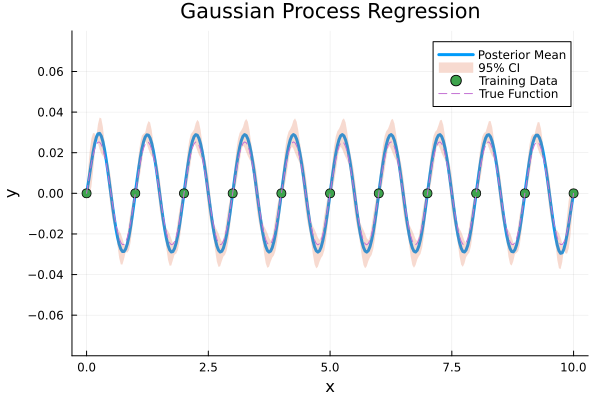

"/Users/shoji/Project_with_Jon/Poisson Equation_1d/a.png"

In [5]:
#-------------------------
# Visualization
# -------------------------
plot(
    X_test,
    μ,
    label="Posterior Mean",
    lw=3
)

plot!(
    X_test,
    μ .+ 1.96 .* std,
    fillrange=μ .- 1.96 .* std,
    fillalpha=0.25,
    linealpha=0,
    label="95% CI"
)

scatter!(
    X_train,
    y_train,
    label="Training Data",
    ms=5
)

plot!(
    X_test,
    #sin.(X_test),
    (1/(2π)^2) * sin.(2π .* X_test),
    ylims = (-0.08, 0.08),
    ls=:dash,
    label="True Function"
)

xlabel!("x")
ylabel!("y")
title!("Gaussian Process Regression")

display(current())

savefig("a.png")

In [6]:
function log_marginal_H(
    X_train,
    y;
    H,
    dt,
    ℓ,
    σf,
    C,
    prior_mean = 0.0
)

    # ノイズ共分散：内点は C*dt^4，境界点は 0（論文 eq. 3.3）
    n_tr = length(X_train)
    noise_diag = fill(C * dt^4, n_tr)
    noise_diag[1]   = 0.0
    noise_diag[end] = 0.0
    Σ_noise = Diagonal(noise_diag)

    K =
        H *
        kernel_matrix(X_train, X_train;
                      ℓ=ℓ,
                      σf=σf) *
        H' +
        Σ_noise

    # 安定化項：境界点（ノイズ=0）は大きめに
    jitter = fill(1e-10, n_tr)
    jitter[1]   = 1e-8
    jitter[end] = 1e-8
    K += Diagonal(jitter)

    m = fill(prior_mean, length(y))

    # PosDefException をキャッチ → -Inf を返してグリッドサーチでスキップ
    local L
    try
        L = cholesky(Hermitian(K)).L
    catch e
        if isa(e, PosDefException)
            return -Inf
        else
            rethrow(e)
        end
    end

    α = L' \ (L \ (y - m))
    logdetK = 2sum(log.(diag(L)))

    return -0.5 * ((y - m)' * α) -
           0.5 * logdetK -
           0.5 * length(y) * log(2π)
end



log_marginal_H (generic function with 1 method)

In [7]:
ℓ_grid = [ 0.0001, 0.001,0.1,0.5,1.0,2.0,5.0,10.0,100.0, 1000]

σf_grid = [0.001,0.01,0.03,
           0.1,0.3,1.0,3.0,
           10.0,30.0,100.0,500.0, 1000.0, 10000.0]

C_grid = [1]

ℓ_grid  = 10 .^ range(-3, 3, length=8)
σf_grid = 10 .^ range(-3, 3, length=8)
C_grid  = 10 .^ range(-3, 3, length=8)

scores = zeros(length(ℓ_grid),
               length(σf_grid),
               length(C_grid))

for (i,ℓ) in enumerate(ℓ_grid)
    for (j,σf) in enumerate(σf_grid)
        for (k,C) in enumerate(C_grid)
            println("parameters:", ℓ, σf, C)

            scores[i,j,k] =
                log_marginal_H(
                    X_train,
                    y_train;
                    H=H,
                    dt=dt,
                    ℓ=ℓ,
                    σf=σf,
                    C=C,
                    prior_mean=0.0
                )

        end
    end
end

best_linear_idx = argmax(scores)
best_I = CartesianIndices(scores)[best_linear_idx]

best_ℓ  = ℓ_grid[best_I[1]]
best_σf = σf_grid[best_I[2]]
best_C  = C_grid[best_I[3]]
println("l=", best_ℓ)
println("σf=", best_σf)
println("C=", best_C)
best_loglik =
    log_marginal_H(
        X_train,
        y_train;
        H=H,
        dt=dt,
        ℓ=best_ℓ,
        σf=best_σf,
        C=best_C,
        prior_mean=0.0
    )

println("log marginal likelihood (best) = ", best_loglik)



parameters:0.0010.0010.001
parameters:0.0010.0010.0071968567300115215
parameters:0.0010.0010.0517947467923121
parameters:0.0010.0010.37275937203149406
parameters:0.0010.0012.6826957952797255
parameters:0.0010.00119.306977288832506
parameters:0.0010.001138.94954943731375
parameters:0.0010.0011000.0
parameters:0.0010.00719685673001152150.001
parameters:0.0010.00719685673001152150.0071968567300115215
parameters:0.0010.00719685673001152150.0517947467923121
parameters:0.0010.00719685673001152150.37275937203149406
parameters:0.0010.00719685673001152152.6826957952797255
parameters:0.0010.007196856730011521519.306977288832506
parameters:0.0010.0071968567300115215138.94954943731375
parameters:0.0010.00719685673001152151000.0
parameters:0.0010.05179474679231210.001
parameters:0.0010.05179474679231210.0071968567300115215
parameters:0.0010.05179474679231210.0517947467923121
parameters:0.0010.05179474679231210.37275937203149406
parameters:0.0010.05179474679231212.6826957952797255
parameters:0.0010.


========== h = 0.3333333333333333 ==========
  best ℓ=0.1,  σf=0.01,  C=10.0,  loglik=3.5381
  MSE_total=0.0002477,  bias²=0.0001994,  var=4.829e-5,  FDM_err=5.139e-5

========== h = 0.25 ==========
  best ℓ=0.1,  σf=0.01,  C=10.0,  loglik=0.60139
  MSE_total=0.0002264,  bias²=0.0001754,  var=5.101e-5,  FDM_err=1.402e-5

========== h = 0.2 ==========
  best ℓ=0.5,  σf=0.1,  C=10.0,  loglik=-0.10022
  MSE_total=0.0005427,  bias²=3.543e-5,  var=0.0005073,  FDM_err=5.442e-6

========== h = 0.16666666666666666 ==========
  best ℓ=0.5,  σf=0.1,  C=10.0,  loglik=0.46789
  MSE_total=0.000362,  bias²=1.529e-5,  var=0.0003468,  FDM_err=2.567e-6

========== h = 0.14285714285714285 ==========
  best ℓ=0.5,  σf=0.1,  C=10.0,  loglik=1.7038
  MSE_total=0.0002483,  bias²=7.176e-6,  var=0.0002412,  FDM_err=1.373e-6

========== h = 0.125 ==========
  best ℓ=0.5,  σf=0.1,  C=10.0,  loglik=3.6387
  MSE_total=0.000176,  bias²=3.791e-6,  var=0.0001722,  FDM_err=8.019e-7

========== h = 0.1111111111111111

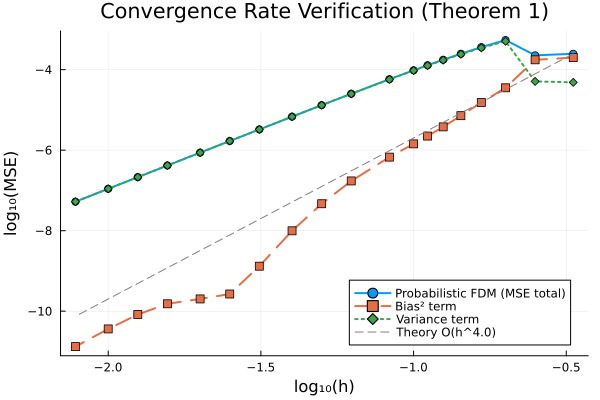

"/Users/shoji/Project_with_Jon/Poisson Equation_1d/convergence_rate.png"

In [8]:
# ============================================================
# 収束実験：h を小さくしながら，各 h でグリッドサーチ → MSE 計測
# ============================================================

τ        = 1.0       # ノイズ分散 = h^(2τ)
κ_theory = 4.0    # 理論収束レート（前回の計算より）

h_list = [1/4, 1/8, 1/16, 1/32, 1/64]
K_list = [3, 4, 5, 6,7, 8, 9, 10, 12, 16, 20, 25, 32, 40, 50, 64, 80, 100, 128]
h_list = 1.0 ./ K_list

# 結果格納
mse_bias_list   = Float64[]
mse_var_list    = Float64[]
mse_total_list  = Float64[]
fdm_error_list  = Float64[]
best_params     = []   # 各 h の最適パラメータを記録

for h in h_list
    println("\n========== h = $h ==========")

    # グリッド（ドメイン [0,1]）
    X = collect(0:h:1.0)
    N = length(X)

    # 真の解・観測
    u_true = (1/(2π)^2) .* sin.(2π .* X)
    f_obs  = zeros(N)
    f_obs[2:end-1] = -sin.(2π .* X[2:end-1])
    f_obs[1]   = 0.0
    f_obs[end] = 0.0

    # 情報演算子 H
    H_h = observation_matrix(N, h)

    # --------------------------------------------------
    # ℓ, σf は狭めに，C は広めにグリッドサーチ
    # ℓ: ドメイン [0,1] に対して 0.1〜1.0（暴れ防止）
    # σf: 解の振幅に合わせて 0.01〜1.0
    # C: 広めに探索（5×4×10=200回）
    # --------------------------------------------------
    ℓ_grid_h  = [0.1, 0.2, 0.3, 0.5, 1.0]
    σf_grid_h = [0.01, 0.1, 0.5, 1.0]
    #C_grid_h  = 10 .^ range(-2, 2, length=10)
    C_grid_h  = 10 .^ range(1, 1, length=1)

    best_score = -Inf
    best_ℓ_h  = ℓ_grid_h[1]
    best_σf_h = σf_grid_h[1]
    best_C_h  = C_grid_h[1]

    for ℓ in ℓ_grid_h, σf in σf_grid_h, C in C_grid_h
        score = log_marginal_H(
            X, f_obs;
            H=H_h, dt=h, ℓ=ℓ, σf=σf, C=C,
            prior_mean=0.0
        )
        if score > best_score
            best_score = score
            best_ℓ_h  = ℓ
            best_σf_h = σf
            best_C_h  = C
        end
    end

    println("  best ℓ=$(round(best_ℓ_h, sigdigits=3)),  σf=$(round(best_σf_h, sigdigits=3)),  C=$(round(best_C_h, sigdigits=3)),  loglik=$(round(best_score, sigdigits=5))")
    push!(best_params, (h=h, ℓ=best_ℓ_h, σf=best_σf_h, C=best_C_h))

    # --------------------------------------------------
    # 最適パラメータで事後分布を計算
    # --------------------------------------------------
    K_prior = kernel_matrix(X, X; ℓ=best_ℓ_h, σf=best_σf_h)

    noise_diag = fill(best_C_h * h^(2τ), N)
    noise_diag[1]   = 0.0
    noise_diag[end] = 0.0
    Σ_noise = Diagonal(noise_diag)

    A_mat = H_h * K_prior * H_h' + Σ_noise
    jitter = fill(1e-10, N)
    jitter[1]   = 1e-12
    jitter[end] = 1e-12
    A_mat += Diagonal(jitter)

    # 事後平均（論文 eq. 3.4）
    α      = A_mat \ f_obs
    μ_post = K_prior * H_h' * α

    # 事後共分散（グリッド点上）
    K_post = K_prior - K_prior * H_h' * (A_mat \ (H_h * K_prior))

    # バイアス項
    bias_sq  = mean((μ_post .- u_true).^2)
    # 分散項
    var_term = tr(K_post) / N
    # 合計 MSE
    mse_total = bias_sq + var_term

    # 通常 FDM の経験ノルム誤差
    n_int = N - 2
    A_fdm = zeros(n_int, n_int)
    for i in 1:n_int
        A_fdm[i,i] = -2.0
        if i > 1;     A_fdm[i,i-1] = 1.0; end
        if i < n_int; A_fdm[i,i+1] = 1.0; end
    end
    A_fdm ./= h^2
    u_fdm   = vcat(0.0, A_fdm \ (-sin.(2π .* X[2:end-1])), 0.0)
    fdm_err = mean((u_fdm .- u_true).^2)

    push!(mse_bias_list,  bias_sq)
    push!(mse_var_list,   var_term)
    push!(mse_total_list, mse_total)
    push!(fdm_error_list, fdm_err)

    println("  MSE_total=$(round(mse_total, sigdigits=4)),  bias²=$(round(bias_sq, sigdigits=4)),  var=$(round(var_term, sigdigits=4)),  FDM_err=$(round(fdm_err, sigdigits=4))")
end

# --------------------------------------------------
# 実測収束レートを推定
# --------------------------------------------------
log_h   = log10.(h_list)
log_mse = log10.(mse_total_list)
log_fdm = log10.(fdm_error_list)

slope_pfm = (log_mse[end] - log_mse[1]) / (log_h[end] - log_h[1])
slope_fdm = (log_fdm[end] - log_fdm[1]) / (log_h[end] - log_h[1])
println("\n実測収束レート（Probabilistic FDM）: κ ≈ $(round(slope_pfm, sigdigits=3))")
println("実測収束レート（標準 FDM）           : κ ≈ $(round(slope_fdm, sigdigits=3))")
println("理論値 κ = $(κ_theory)")

# --------------------------------------------------
# log-log プロット
# --------------------------------------------------
ref_pfm = log_mse[1] .+ κ_theory .* (log_h .- log_h[1])

p = plot(
    log_h, log_mse,
    marker=:circle, lw=2, label="Probabilistic FDM (MSE total)",
    xlabel="log₁₀(h)", ylabel="log₁₀(MSE)",
    title="Convergence Rate Verification (Theorem 1)",
    legend=:bottomright
)
plot!(p, log_h, log10.(mse_bias_list),
    marker=:square, lw=2, ls=:dash, label="Bias² term")
plot!(p, log_h, log10.(mse_var_list),
    marker=:diamond, lw=2, ls=:dot, label="Variance term")
#plot!(p, log_h, log_fdm,
#    marker=:cross, lw=2, label="Standard FDM (MSE)")
plot!(p, log_h, ref_pfm,
    lw=1, ls=:dash, color=:gray,
    label="Theory O(h^$(κ_theory))")

display(p)
savefig(p, "convergence_rate.png")



==================== τ = 3 ====================
  実測 κ ≈ 4.45,  理論 κ = 4.0

==================== τ = 2 ====================
  実測 κ ≈ 4.45,  理論 κ = 4.0

==================== τ = 1 ====================
  実測 κ ≈ 3.79,  理論 κ = 3.0

==================== τ = 0 ====================
  実測 κ ≈ 1.24,  理論 κ = 1.0


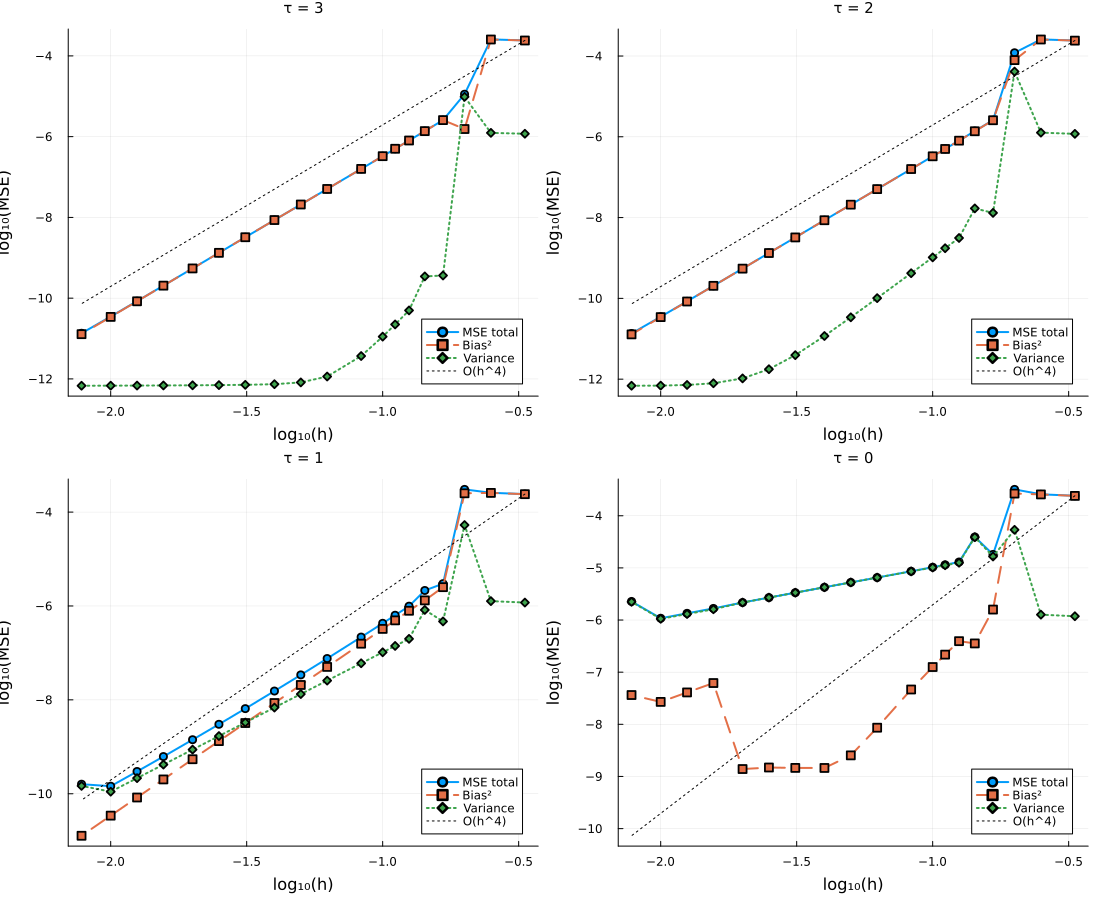

"/Users/shoji/Project_with_Jon/Poisson Equation_1d/convergence_tau_comparison.png"

In [9]:
# ============================================================
# τ = 3, 2, 1, 0 で収束実験を回して 2×2 で並べる
# 各パネルに O(h^4) の参照線も追加
# ============================================================

τ_list   = [3, 2, 1, 0]
κ_theory_list = Dict(
    3 => 4.0,
    2 => 4.0,
    1 => 3.0,
    0 => 1.0
)

K_list = [3, 4, 5, 6, 7, 8, 9, 10, 12, 16, 20, 25, 32, 40, 50, 64, 80, 100, 128]
h_list = 1.0 ./ K_list

plots_list = []

for τ in τ_list
    println("\n==================== τ = $τ ====================")

    κ_theory = get(κ_theory_list, τ, 1.0)

    mse_bias_list  = Float64[]
    mse_var_list   = Float64[]
    mse_total_list = Float64[]
    fdm_error_list = Float64[]

    for h in h_list
        X = collect(0:h:1.0)
        N = length(X)

        u_true = (1/(2π)^2) .* sin.(2π .* X)
        f_obs  = zeros(N)
        f_obs[2:end-1] = -sin.(2π .* X[2:end-1])
        f_obs[1]   = 0.0
        f_obs[end] = 0.0

        H_h = observation_matrix(N, h)

        ℓ_grid_h  = [0.1, 0.2, 0.3, 0.5, 1.0]
        σf_grid_h = [0.01, 0.1, 0.5, 1.0]
        C_grid_h  = 10 .^ range(-2, 2, length=10)

        best_score = -Inf
        best_ℓ_h  = ℓ_grid_h[1]
        best_σf_h = σf_grid_h[1]
        best_C_h  = C_grid_h[1]

        for ℓ in ℓ_grid_h, σf in σf_grid_h, C in C_grid_h
            score = log_marginal_H(
                X, f_obs;
                H=H_h, dt=h, ℓ=ℓ, σf=σf, C=C,
                prior_mean=0.0
            )
            if score > best_score
                best_score = score
                best_ℓ_h  = ℓ
                best_σf_h = σf
                best_C_h  = C
            end
        end

        K_prior = kernel_matrix(X, X; ℓ=best_ℓ_h, σf=best_σf_h)

        noise_diag = fill(best_C_h * h^(2τ), N)
        noise_diag[1]   = 0.0
        noise_diag[end] = 0.0
        Σ_noise = Diagonal(noise_diag)

        A_mat = H_h * K_prior * H_h' + Σ_noise
        jitter = fill(1e-10, N)
        jitter[1]   = 1e-12
        jitter[end] = 1e-12
        A_mat += Diagonal(jitter)

        α      = A_mat \ f_obs
        μ_post = K_prior * H_h' * α
        K_post = K_prior - K_prior * H_h' * (A_mat \ (H_h * K_prior))

        bias_sq  = mean((μ_post .- u_true).^2)
        var_term = tr(K_post) / N
        mse_total = bias_sq + var_term

        n_int = N - 2
        A_fdm = zeros(n_int, n_int)
        for i in 1:n_int
            A_fdm[i,i] = -2.0
            if i > 1;     A_fdm[i,i-1] = 1.0; end
            if i < n_int; A_fdm[i,i+1] = 1.0; end
        end
        A_fdm ./= h^2
        u_fdm   = vcat(0.0, A_fdm \ (-sin.(2π .* X[2:end-1])), 0.0)
        fdm_err = mean((u_fdm .- u_true).^2)

        push!(mse_bias_list,  bias_sq)
        push!(mse_var_list,   var_term)
        push!(mse_total_list, mse_total)
        push!(fdm_error_list, fdm_err)
    end

    log_h   = log10.(h_list)
    log_mse = log10.(mse_total_list)
    log_fdm = log10.(fdm_error_list)

    slope_pfm = (log_mse[end] - log_mse[1]) / (log_h[end] - log_h[1])
    println("  実測 κ ≈ $(round(slope_pfm, sigdigits=3)),  理論 κ = $κ_theory")

    # 理論収束レートの参照線
    ref_theory = log_mse[1] .+ κ_theory .* (log_h .- log_h[1])
    # O(h^4) の比較参照線
    ref_4      = log_mse[1] .+ 4.0      .* (log_h .- log_h[1])

    p = plot(
        log_h, log_mse,
        marker=:circle, lw=2, label="MSE total",
        xlabel="log₁₀(h)", ylabel="log₁₀(MSE)",
        title="τ = $τ",
        legend=:bottomright,
        titlefontsize=10
    )
    plot!(p, log_h, log10.(mse_bias_list),
        marker=:square, lw=2, ls=:dash, label="Bias²")
    plot!(p, log_h, log10.(mse_var_list),
        marker=:diamond, lw=2, ls=:dot, label="Variance")
    #plot!(p, log_h, log_fdm,
    #    marker=:cross, lw=2, label="Standard FDM")
    #plot!(p, log_h, ref_theory,
    #    lw=1, ls=:dash, color=:gray,
    #    label="O(h^$(κ_theory))")
    plot!(p, log_h, ref_4,
        lw=1, ls=:dot, color=:black,
        label="O(h^4)")

    push!(plots_list, p)
end

p_all = plot(plots_list..., layout=(2,2), size=(1100, 900))
display(p_all)
savefig(p_all, "convergence_tau_comparison.png")
